# 10.2.4 配套实验：反转学习中的 RW 与 GRU

在反转学习任务中，个体需要根据不断获得的奖励调整选择。经典强化学习模型用预先规定的规则描述这一过程，循环神经网络则通过拟合行为数据学习状态更新的方式。本实验以猴子的选择行为为例，比较 RW 模型与两隐藏单元 GRU 的预测，并分析两者在相同反馈下的状态变化。

完成本实验后，应能够将行为记录整理为保留实验块边界的序列，说明模型预测与反馈更新的时间关系，并结合测试表现和状态动力学讨论模型的学习规则。实验内容与教材第 10 章第 10.2.4 节对应。

## 1. 实验准备

本实验使用 Python、NumPy 和 PyTorch。数据、配套程序与插图应保留在下载资料的原有目录中。在资料根目录运行以下命令可启动实验：

```bash
uv run --group notebook jupyter lab doc/reversal_learning.ipynb
```

各代码单元按文中顺序执行。默认设置读取已拟合的参数，复现预测与动力学结果；将 `FIT_MODELS` 设为 `True` 可重新估计参数。重新拟合的结果保存于 `results/notebook/`，读取位置由 `SAVED_RESULTS_DIR` 指定。

In [1]:
import sys
from collections import Counter
from contextlib import redirect_stdout
from io import StringIO
from pathlib import Path
from xml.etree import ElementTree

import numpy as np
import torch
from IPython.display import SVG, Markdown, display

# 确定配套资料根目录，以相对位置定位程序、数据和插图。
PROJECT_DIR = None
for candidate in [Path.cwd(), *Path.cwd().parents]:
    if (candidate / "src" / "rl_rnn_example").is_dir():
        PROJECT_DIR = candidate
        break
if PROJECT_DIR is None:
    raise FileNotFoundError("未找到配套程序，请从资料根目录或 doc 目录启动实验。")

sys.path.insert(0, str(PROJECT_DIR / "src"))

from rl_rnn_example.dataset import load_blocks
from rl_rnn_example.rw import RWModel
from rl_rnn_example.gru import GRUModel
from rl_rnn_example.training import split_blocks, fit_rw, fit_gru
from rl_rnn_example.metrics import evaluate
from rl_rnn_example.analysis import (
    load_results,
    save_results,
    collect_predictions,
    summarize_model_comparison,
    compute_model_dynamics,
    save_figure_captions,
)
from rl_rnn_example.plotting import (
    plot_model_comparison,
    plot_dynamics_comparison,
)


def show_table(headers, rows):
    """将表头与记录显示为 Markdown 表格。"""
    lines = ["| " + " | ".join(headers) + " |"]
    lines.append("| " + " | ".join(["---"] * len(headers)) + " |")
    for row in rows:
        lines.append("| " + " | ".join(str(value) for value in row) + " |")
    display(Markdown("\n".join(lines)))


def show_svg(path):
    """检查并显示 SVG 矢量插图。"""
    svg = ElementTree.parse(path).getroot()
    if svg.findall(".//{http://www.w3.org/2000/svg}image"):
        raise ValueError(f"SVG 插图包含位图元素：{path}")
    display(SVG(filename=str(path)))


print("Python 版本：", sys.version.split()[0])
print("PyTorch 版本：", torch.__version__)

Python 版本： 3.13.15
PyTorch 版本： 2.14.1


In [2]:
# False：使用预先拟合的参数；True：重新估计两种模型的参数。
FIT_MODELS = False

ANIMAL_NAME = "V"
TRIAL_START = 11
TRIAL_END = 70
SEED = 0
VALIDATION_FRACTION = 0.1
TEST_FRACTION = 0.1

HIDDEN_DIM = 2
LEARNING_RATE = 0.005
MAX_EPOCHS = 1000
PATIENCE = 100

GRID_SIZE = 41
MAX_ARROWS_PER_CONDITION = None  # 显示全部测试事件。
DYNAMICS_SAMPLE_SEED = 0

DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "results" / "notebook" / f"monkey_{ANIMAL_NAME}_seed{SEED}"
# 预先拟合参数的读取位置。
# 读取本实验重新估计的参数时，设 SAVED_RESULTS_DIR = OUTPUT_DIR。
SAVED_RESULTS_DIR = PROJECT_DIR / "results" / f"monkey_{ANIMAL_NAME}_seed{SEED}"
FIGURE_DIR = OUTPUT_DIR / "figures"
CHAPTER_FIGURE_DIR = PROJECT_DIR / "doc" / "figures"

if HIDDEN_DIM != 2:
    raise ValueError("二维状态动力学要求 HIDDEN_DIM = 2。")

print("参数来源：", "重新估计" if FIT_MODELS else "预先拟合结果")

参数来源： 预先拟合结果


## 2. 反转学习任务与行为数据

猴子在每次试次中选择两个选项之一，随后获得奖励或无奖励反馈。每个完整实验块（block）包含 80 次试次，两个选项的奖励概率分别为 0.7 和 0.3，并在 block 中部的一个随机试次无提示地互换（Bartolo 等，2020）。由于奖励具有概率性，一次无奖励并不足以确定环境已经发生反转。

任务包含两种条件：what block 的奖励概率与图像身份有关，where block 的奖励概率与空间位置有关。数据整理时分别依据图像或位置将选择编码为动作 0 和动作 1，奖励编码为 1，无奖励编码为 0。动作 0 的含义因任务条件而异。

数据文件按实验场次（session）保存，每个 session 包含多个 block。以下分析使用猴子 V 的 4 个 session，共 96 个完整 block。每个 block 保留原始第 11–70 次试次，共 60 次。模型在保留序列的起点将状态初始化为零，反转时继续更新；这一处理不包含前 10 次试次的行为历史。

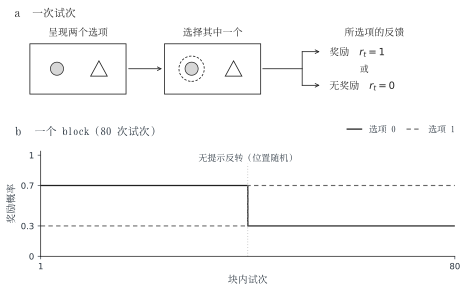

In [3]:
show_svg(CHAPTER_FIGURE_DIR / "reversal_task.svg")

**图 1　反转学习任务。** 单次试次包含呈现、选择与反馈；一个 block 内两选项的奖励概率互换一次。图中刺激和反转位置均为示意。

In [4]:
# 读取行为数据，文件列表日志暂存于内存。
with redirect_stdout(StringIO()):
    blocks = load_blocks(
        data_dir=DATA_DIR,
        animal_name=ANIMAL_NAME,
        trial_start=TRIAL_START,
        trial_end=TRIAL_END,
    )

session_counts = Counter(block["session_name"] for block in blocks)
show_table(["session", "完整 block 数"], sorted(session_counts.items()))
print("合计 block 数：", len(blocks))
print("每个 block 保留的试次数：", sorted({len(block["actions"]) for block in blocks}))

# 动作与奖励构成模型输入；其他字段标识数据来源。
example = blocks[0]
print("记录示例：", example["session_name"], "block", example["block_order"], example["block_type"])
rows = []
for t in range(min(10, len(example["actions"]))):
    rows.append([
        example["trial_numbers"][t],
        example["actions"][t],
        example["rewards"][t],
    ])
show_table(["原始试次编号", "动作 a", "奖励 r"], rows)

| session | 完整 block 数 |
| --- | --- |
| V20160929 | 24 |
| V20160930 | 24 |
| V20161005 | 24 |
| V20161017 | 24 |

合计 block 数： 96
每个 block 保留的试次数： [60]
记录示例： V20160929 block 1 where


| 原始试次编号 | 动作 a | 奖励 r |
| --- | --- | --- |
| 11 | 0 | 0 |
| 12 | 0 | 1 |
| 13 | 0 | 1 |
| 14 | 0 | 0 |
| 15 | 0 | 0 |
| 16 | 1 | 0 |
| 17 | 0 | 0 |
| 18 | 1 | 0 |
| 19 | 1 | 0 |
| 20 | 0 | 0 |

## 3. 数据划分与输入格式

训练集用于估计参数，验证集用于选择 GRU 的训练停止时机，测试集用于评价最终预测。数据按完整 block 划分，各 block 内的试次顺序保持不变。默认随机种子下，三个集合分别包含 78、9 和 9 个 block。

一个 block 由猴子编号、session 名称和该 session 内的 block 序号共同标识。下列代码检查三个集合的 block 是否互不重叠，并统计各集合的试次数。

In [5]:
train_blocks, validation_blocks, test_blocks = split_blocks(
    blocks,
    validation_fraction=VALIDATION_FRACTION,
    test_fraction=TEST_FRACTION,
    seed=SEED,
)
splits = {
    "train": train_blocks,
    "validation": validation_blocks,
    "test": test_blocks,
}


def block_ids(block_list):
    """按原有顺序返回猴子、session 和 session 内 block 序号。"""
    return [
        (block["animal_name"], block["session_name"], block["block_order"])
        for block in block_list
    ]


train_ids = set(block_ids(train_blocks))
validation_ids = set(block_ids(validation_blocks))
test_ids = set(block_ids(test_blocks))
assert train_ids.isdisjoint(validation_ids)
assert train_ids.isdisjoint(test_ids)
assert validation_ids.isdisjoint(test_ids)
assert len(train_ids | validation_ids | test_ids) == len(blocks)

show_table(
    ["集合", "block 数", "试次数"],
    [
        [name, len(group), sum(len(block["actions"]) for block in group)]
        for name, group in splits.items()
    ],
)

| 集合 | block 数 | 试次数 |
| --- | --- | --- |
| train | 78 | 4680 |
| validation | 9 | 540 |
| test | 9 | 540 |

GRU 的批量输入形状为 `(T, B, 2)`。其中，`T` 表示保留的试次数，`B` 表示 block 数，最后一维依次存放动作与奖励。预测目标 `targets` 的形状为 `(T, B)`，每个元素是对应试次的真实动作。

不同 block 沿批量维度排列，各自保持独立的状态序列。预测当前动作时只能使用此前的行为历史；这一时间约束由后文的状态对齐操作实现。

In [6]:
train_inputs = np.stack(
    [np.stack([block["actions"], block["rewards"]], axis=-1) for block in train_blocks],
    axis=1,
)
train_targets = np.stack([block["actions"] for block in train_blocks], axis=1)

print("inputs：", train_inputs.shape)
print("targets：", train_targets.shape)
print("第一个训练 block 的前 5 组 [动作, 奖励]：")
print(train_inputs[:5, 0, :])

inputs： (60, 78, 2)
targets： (60, 78)
第一个训练 block 的前 5 组 [动作, 奖励]：
[[1 0]
 [0 0]
 [0 1]
 [1 0]
 [0 1]]


## 4. RW 模型：价值预测与反馈更新

令 $Q_t(a)$ 表示第 $t$ 次选择前对动作 $a$ 的价值估计。模型将两个动作的价值通过 softmax 转换为选择概率：

$$
p_t(a)=\frac{\exp[\beta Q_t(a)]}{\exp[\beta Q_t(0)]+\exp[\beta Q_t(1)]}.
$$

其中，逆温度 $\beta$ 控制选择对价值差异的敏感程度。观察到动作 $a_t$ 与奖励 $r_t$ 后，被选动作的价值更新为

$$
Q_{t+1}(a_t)=Q_t(a_t)+\alpha[r_t-Q_t(a_t)],
$$

未选动作的价值保持不变。学习率 $\alpha$ 决定新反馈对价值估计的影响。代码中的 `iTemp` 对应逆温度 $\beta$。

`rw_predict_block` 将选择预测与价值更新写在同一循环中。每次循环先保存当前状态并计算选择概率，再读取该试次的动作与奖励。所有训练 block 共同确定 $\alpha$ 和 $\beta$，各 block 的价值状态则独立演化。

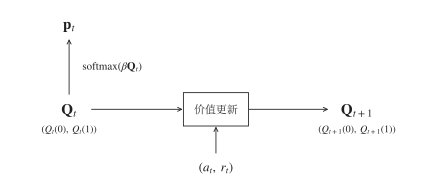

In [7]:
show_svg(CHAPTER_FIGURE_DIR / "rw_architecture.svg")

**图 2　RW 模型。** 当前价值状态产生选择概率，真实动作与奖励用于更新下一状态。每次更新只改变被选动作的价值。

In [8]:
def rw_predict_block(model, actions, rewards):
    """计算一个 block 的选择概率及反馈前后的价值状态。"""
    values = np.zeros(2)
    probabilities = []
    states = []

    for t in range(len(actions)):
        # 根据反馈前的价值预测当前选择。
        states.append(values.copy())
        scores = model.iTemp * (values - values.max())
        weights = np.exp(scores)
        probabilities.append(weights / weights.sum())

        # 读取反馈，只更新被选动作的价值。
        action = actions[t]
        reward = rewards[t]
        prediction_error = reward - values[action]
        values[action] += model.alpha * prediction_error

    return {
        "probabilities": np.array(probabilities),
        "states": np.array(states),
        "final_state": values.copy(),
    }

## 5. GRU 模型：隐藏状态与门控更新

GRU 用隐藏状态 $\mathbf h_t$ 概括此前的行为历史。本实验将隐藏维度设为 2，并通过线性读出层产生两个动作分数，再用 softmax 得到选择概率：

$$
\mathbf p_t=\operatorname{softmax}(W_{\mathrm{out}}\mathbf h_t+\mathbf b_{\mathrm{out}}).
$$

模型由 `nn.GRU(input_size=2, hidden_size=2)` 和 `nn.Linear(2, 2)` 组成，共有 42 个可训练参数。二维状态便于在平面上观察更新过程，但两个隐藏坐标没有预先指定的价值含义。

GRU 读取本次输入 $\mathbf x_t=(a_t,r_t)^\mathsf T$ 后，输出的是下一状态 $\mathbf h_{t+1}$。预测当前动作时，应使用读取该输入之前的 $\mathbf h_t$。因此，`gru_predict_batch` 在状态序列开头加入零初始状态，并移除最后一项，使状态与预测目标正确对应。

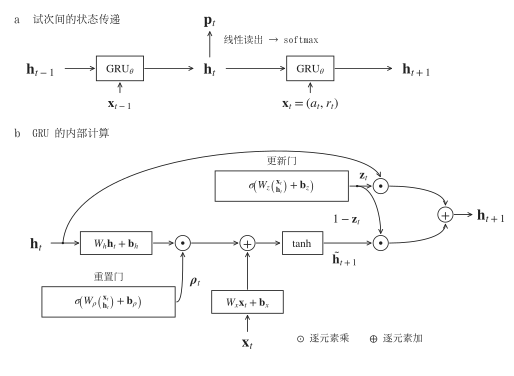

In [9]:
show_svg(CHAPTER_FIGURE_DIR / "gru_architecture.svg")

**图 3　GRU 模型。** 上图表示试次间的状态传递与选择读出，下图展开一次门控更新。$\odot$ 表示逐元素乘，圈内加号表示逐元素加。

In [10]:
def gru_predict_batch(model, inputs):
    """计算一批 block 的动作分数与状态，并保留训练所需的梯度。"""
    # 每个 block 都有独立的零初始状态。
    h0 = torch.zeros(
        1, inputs.size(1), model.hidden_dim,
        dtype=inputs.dtype, device=inputs.device,
    )
    updated_states, final_state = model.gru(inputs, h0)

    # 用反馈前的状态预测当前动作，将 GRU 输出向后对齐一位。
    states = torch.cat([h0, updated_states[:-1]], dim=0)
    logits = model.linear(states)

    return {
        "logits": logits,
        "states": states,
        "final_state": final_state.squeeze(0),
    }

GRU 通过重置门与更新门调节历史信息。为说明内部运算，将当前输入和旧状态分别经过矩阵乘法与偏置得到的结果记为 $\mathbf i$ 和 $\mathbf g$。两者各包含重置门、更新门和候选状态三个分支。门值的计算为

$$
\boldsymbol\rho_t=\sigma(\mathbf i_\rho+\mathbf g_\rho),\qquad
\mathbf z_t=\sigma(\mathbf i_z+\mathbf g_z),
$$

候选状态与下一状态为

$$
\widetilde{\mathbf h}_{t+1}=\tanh(\mathbf i_n+\boldsymbol\rho_t\odot\mathbf g_n),
$$
$$
\mathbf h_{t+1}=\mathbf z_t\odot\mathbf h_t+(1-\mathbf z_t)\odot\widetilde{\mathbf h}_{t+1}.
$$

$\sigma$ 为 sigmoid 函数，将门值限制在 0 与 1 之间；$\odot$ 表示逐元素乘法。重置门调节变换后的旧状态对候选状态的贡献，更新门决定旧状态与候选状态的混合比例。两个门均依赖当前输入和旧状态，因此相同反馈可以在不同历史状态下产生不同更新。

以下计算采用 PyTorch 的 GRU 定义：重置门作用于旧状态的矩阵变换与偏置之和。参数按重置门、更新门、候选状态的顺序排列，`chunk(3)` 将相应分支分开。

In [11]:
def gru_update_state(model, state, action, reward):
    """根据重置门、更新门和候选状态计算一次状态更新。"""
    parameter = next(model.parameters())
    x = torch.tensor([action, reward], dtype=parameter.dtype, device=parameter.device)
    h = torch.tensor(state, dtype=parameter.dtype, device=parameter.device)

    with torch.no_grad():
        input_parts = (
            model.gru.weight_ih_l0 @ x + model.gru.bias_ih_l0
        )
        hidden_parts = (
            model.gru.weight_hh_l0 @ h + model.gru.bias_hh_l0
        )
        input_reset, input_update, input_candidate = input_parts.chunk(3)
        hidden_reset, hidden_update, hidden_candidate = hidden_parts.chunk(3)

        reset_gate = torch.sigmoid(input_reset + hidden_reset)
        update_gate = torch.sigmoid(input_update + hidden_update)
        candidate = torch.tanh(input_candidate + reset_gate * hidden_candidate)
        next_state = update_gate * h + (1 - update_gate) * candidate

    return next_state.cpu().numpy()

## 6. 参数估计

两种模型均以提高真实选择的预测概率为目标。RW 在训练集上估计 $\alpha$ 和 $\beta$；GRU 通过反向传播更新权重，并保留验证集负对数似然最低时的参数。测试集用于拟合结束后的评价。

应区分参数估计与任务中的状态变化：训练时，GRU 的权重随优化过程改变；分析行为时，权重固定，隐藏状态随动作与奖励逐次更新。代码中的 `LEARNING_RATE` 控制优化器的步长，与 RW 学习率 $\alpha$ 的行为含义不同。

`RWModel` 与 `GRUModel` 封装了前述更新规则，`fit_rw` 与 `fit_gru` 完成参数估计。读取预先拟合的结果时，程序检查数据定义和 block 划分是否与保存记录一致。

In [12]:
config = {
    "animal_name": ANIMAL_NAME,
    "trial_start": TRIAL_START,
    "trial_end": TRIAL_END,
    "seed": SEED,
    "validation_fraction": VALIDATION_FRACTION,
    "test_fraction": TEST_FRACTION,
    "hidden_dim": HIDDEN_DIM,
    "learning_rate": LEARNING_RATE,
    "max_epochs": MAX_EPOCHS,
    "patience": PATIENCE,
    "grid_size": GRID_SIZE,
    "max_arrows_per_condition": MAX_ARROWS_PER_CONDITION,
    "dynamics_sample_seed": DYNAMICS_SAMPLE_SEED,
}
saved_records = None

if FIT_MODELS:
    rw_model = RWModel()
    print("正在拟合 RW……", flush=True)
    fit_rw(rw_model, train_blocks)

    torch.manual_seed(SEED)
    gru_model = GRUModel(hidden_dim=HIDDEN_DIM)
    print("正在拟合 GRU……", flush=True)
    history = fit_gru(
        gru_model,
        train_blocks,
        validation_blocks,
        learning_rate=LEARNING_RATE,
        max_epochs=MAX_EPOCHS,
        patience=PATIENCE,
    )
    models = {"RW": rw_model, "GRU": gru_model}
else:
    if not (SAVED_RESULTS_DIR / "experiment.json").is_file():
        raise FileNotFoundError("未找到预先拟合的结果。设 FIT_MODELS = True 可重新估计参数。")
    models, saved_records, experiment = load_results(SAVED_RESULTS_DIR)
    history = experiment["training_history"]

    # 核对参数估计时的数据定义、集合划分和模型维度。
    for name in (
        "animal_name", "trial_start", "trial_end", "seed",
        "validation_fraction", "test_fraction", "hidden_dim",
    ):
        if experiment["config"][name] != config[name]:
            raise ValueError(f"配置 {name} 与保存记录不一致，需使用匹配配置或重新估计参数。")
    for name, group in splits.items():
        assert block_ids(group) == block_ids(experiment["splits"][name]), name
    assert block_ids(test_blocks) == block_ids(saved_records)
    for block, record in zip(test_blocks, saved_records):
        for name in ("actions", "rewards", "trial_numbers"):
            np.testing.assert_array_equal(block[name], record[name])
    print("参数读取完成，数据定义与划分一致。")

print(models["GRU"])
print("GRU 参数数量：", sum(parameter.numel() for parameter in models["GRU"].parameters()))
print("验证 NLL 最低的训练轮次：", history["best_epoch"])
print(f"RW：alpha = {models['RW'].alpha:.6f}，iTemp = {models['RW'].iTemp:.6f}")

参数读取完成，数据定义与划分一致。
GRUModel(
  (gru): GRU(2, 2)
  (linear): Linear(in_features=2, out_features=2, bias=True)
)
GRU 参数数量： 42
验证 NLL 最低的训练轮次： 571
RW：alpha = 0.445283，iTemp = 3.387289


## 7. 选择预测与状态轨迹

参数确定后，分别计算各测试 block 的逐试次选择概率和内部状态。`states[t]` 表示第 $t$ 次反馈前的状态，`final_state` 保存最后一次反馈后的状态。一个包含 $T$ 次试次的 block 因而对应 $T$ 组预测与 $T+1$ 个状态位置。

这些记录同时用于预测评价和动力学分析。显式计算与封装方法的一致性检查列于附录。

In [13]:
records = collect_predictions(models, test_blocks)
n_test_trials = sum(len(record["actions"]) for record in records)
show_table(
    ["模型", "选择概率形状", "反馈前状态形状", "末状态形状"],
    [
        [name, prediction["probabilities"].shape, prediction["states"].shape, prediction["final_state"].shape]
        for name, prediction in records[0]["models"].items()
    ],
)
print(f"测试记录：{len(records)} 个 block，{n_test_trials} 次试次。")

| 模型 | 选择概率形状 | 反馈前状态形状 | 末状态形状 |
| --- | --- | --- | --- |
| RW | (60, 2) | (60, 2) | (2,) |
| GRU | (60, 2) | (60, 2) | (2,) |

测试记录：9 个 block，540 次试次。


## 8. 测试集上的预测表现

预测评价使用每试次平均负对数似然（negative log-likelihood，NLL）：

$$
\mathrm{NLL}=-\frac{1}{N}\sum_{t=1}^{N}\ln p_t(a_t),
$$

其中，$N$ 为测试试次数，$p_t(a_t)$ 为模型赋予真实选择的概率。NLL 越低，表示模型整体上为真实选择分配的概率越高。

选择准确率统计预测概率最大的动作与真实动作相同的比例。与准确率相比，NLL 还反映预测的确信程度。两个指标均按测试试次汇总，用于比较同一组行为数据上的预测表现。

| 模型 | 测试试次数 | 平均 NLL | 选择准确率 |
| --- | --- | --- | --- |
| RW | 540 | 0.400852 | 82.22% |
| GRU | 540 | 0.367249 | 84.07% |

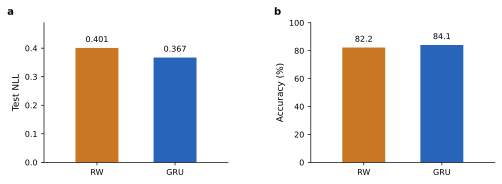

In [14]:
metrics = {}
for model_name, model in models.items():
    metrics[model_name] = evaluate(model, test_blocks)

show_table(
    ["模型", "测试试次数", "平均 NLL", "选择准确率"],
    [
        [name, score["n_trials"], f"{score['nll']:.6f}", f"{score['accuracy']:.2%}"]
        for name, score in metrics.items()
    ],
)

# 保存新估计的参数、数据划分、预测及训练记录。
if FIT_MODELS:
    save_results(OUTPUT_DIR, models, records, config, splits, metrics, history)
    print("参数与预测已保存。")

comparison = summarize_model_comparison(records)
plot_model_comparison(comparison, FIGURE_DIR)
show_svg(FIGURE_DIR / "model_comparison.svg")

**图 4　测试集预测表现。** 两个模型评价同一组测试试次。平均 NLL 越低，表示模型整体上赋予真实选择的概率越高；选择准确率越高，表示预测正确的试次比例越大。

## 9. 条件状态动力学

预测表现说明模型能否描述行为，状态动力学进一步揭示这种预测如何由内部更新产生。固定拟合后的参数，将一次更新写为

$$
\mathbf s_{t+1}=F_{a,r}(\mathbf s_t),\qquad
\Delta\mathbf s=F_{a,r}(\mathbf s_t)-\mathbf s_t.
$$

RW 的状态为 $(Q(0),Q(1))$，GRU 的状态为 $(h_1,h_2)$。动作和奖励均取 0 或 1，因此共有四种输入条件。将全部测试 block 中属于同一条件的更新汇总，可以观察相同反馈在不同起始状态下的作用。

状态差分在各 block 内分别计算。末状态用于补全最后一次更新，不同 block 之间的初始化过程不计为学习更新。

In [15]:
# 分别计算各 block 内的状态差，再汇总测试事件。
observed_updates = {}
for model_name in models:
    changes_by_block = []
    for record in records:
        prediction = record["models"][model_name]
        complete_states = np.vstack([
            prediction["states"],
            prediction["final_state"],
        ])
        changes = complete_states[1:] - complete_states[:-1]
        assert len(changes) == len(record["actions"])
        changes_by_block.append(changes)
    observed_updates[model_name] = np.concatenate(changes_by_block)
    print(model_name, "状态更新数组形状：", observed_updates[model_name].shape)

event_counts = Counter()
for record in records:
    event_counts.update(zip(record["actions"].tolist(), record["rewards"].tolist()))
show_table(
    ["动作 a", "奖励 r", "整个测试集的事件数"],
    [[action, reward, event_counts[(action, reward)]] for action, reward in [(0, 0), (0, 1), (1, 0), (1, 1)]],
)
assert sum(event_counts.values()) == n_test_trials

RW 状态更新数组形状： (540, 2)
GRU 状态更新数组形状： (540, 2)


| 动作 a | 奖励 r | 整个测试集的事件数 |
| --- | --- | --- |
| 0 | 0 | 101 |
| 0 | 1 | 188 |
| 1 | 0 | 116 |
| 1 | 1 | 135 |

In [16]:
fields = {}
for model_name, model in models.items():
    state_limits = (0.0, 1.0) if model_name == "RW" else (-1.0, 1.0)
    fields[model_name] = compute_model_dynamics(
        model=model,
        records=records,
        model_name=model_name,
        grid_size=GRID_SIZE,
        state_limits=state_limits,
        max_arrows_per_condition=MAX_ARROWS_PER_CONDITION,
        sample_seed=DYNAMICS_SAMPLE_SEED,
    )
    field = fields[model_name]
    assert field["n_trials"] == n_test_trials
    assert sum(condition["n_observed"] for condition in field["conditions"]) == n_test_trials
    if MAX_ARROWS_PER_CONDITION is None:
        assert sum(condition["n_displayed"] for condition in field["conditions"]) == n_test_trials

# 两种模型显示同一组真实动作与奖励事件。
for rw_condition, gru_condition in zip(fields["RW"]["conditions"], fields["GRU"]["conditions"]):
    np.testing.assert_array_equal(rw_condition["event_indices"], gru_condition["event_indices"])

plot_dynamics_comparison(fields, FIGURE_DIR)
save_figure_captions(comparison, fields, FIGURE_DIR)
show_svg(FIGURE_DIR / "dynamics_comparison.svg")

**图 5　整个测试集的条件状态动力学。** 上排为 RW，下排为 GRU，四列对应四种动作与奖励组合。黑箭头为实际反馈驱动的更新，背景与细等值线表示更新幅度，橙色虚线为两个动作的等概率边界。

每个面板固定一种动作与奖励条件。黑箭头表示真实测试历史驱动的模型更新，箭头起点和终点分别对应反馈前后的状态。背景颜色与细等值线表示假设状态下的更新幅度 $\|F_{a,r}(\mathbf s)-\mathbf s\|$。等值线连接幅度相同的位置，并不表示随时间发展的轨迹；背景网格也不意味着所有位置均被实际访问。

橙色虚线表示两个动作等概率的状态。RW 的边界为 $Q(0)=Q(1)$，GRU 的边界由拟合后的线性读出参数决定。状态相对边界的移动有助于解释选择偏好的变化。

同一模型的四个面板共用幅度色标。由于 Q 值与 GRU 隐藏状态的坐标单位不同，跨模型比较时应考察选择概率的变化，而不直接依据颜色或箭头长度判断学习速度。

## 10. 结果分析与讨论

首先比较两个模型的测试 NLL 和选择准确率，再结合动力学图考察其更新规则。RW 的每次反馈仅改变被选动作的价值，更新方向沿相应坐标轴；GRU 的更新可以同时改变两个隐藏坐标，其方向和幅度由当前状态与输入共同决定。GRU 的隐藏坐标不直接等同于两个动作价值。

若 GRU 的测试 NLL 较低，说明它在本次划分中比所用 RW 基线更好地描述了选择。动力学图提供了进一步分析这种差异的线索，但预测优势本身尚不足以确定动物采用了何种机制。

本实验在同一只猴子的既有 session 中留出测试 block。对新 session、新个体以及其他经典模型的比较，需要相应的独立检验。由网络更新提出的认知解释，也需要通过后续模型比较加以检验。

In [17]:
rw_score = metrics["RW"]
gru_score = metrics["GRU"]
print(f"RW：NLL = {rw_score['nll']:.4f}，选择准确率 = {rw_score['accuracy']:.2%}")
print(f"GRU：NLL = {gru_score['nll']:.4f}，选择准确率 = {gru_score['accuracy']:.2%}")
print(f"NLL 差值（RW − GRU）：{rw_score['nll'] - gru_score['nll']:.4f}")
print(f"准确率差值（GRU − RW）：{100 * (gru_score['accuracy'] - rw_score['accuracy']):.2f} 个百分点")

RW：NLL = 0.4009，选择准确率 = 82.22%
GRU：NLL = 0.3672，选择准确率 = 84.07%
NLL 差值（RW − GRU）：0.0336
准确率差值（GRU − RW）：1.85 个百分点


### 思考与练习

1. 根据 RW 的更新公式，说明“选择动作 0、未获奖励”时箭头为何沿水平方向移动，更新幅度如何随当前价值改变。
2. 在 GRU 的同一输入条件下，比较两个起始状态的更新。结合等概率边界，判断这些更新是否都增强了相同的选择偏好。
3. 将 `SEED` 改为另一个整数并重新拟合，比较测试表现与动力学图。哪些结果较为稳定，哪些结果依赖本次数据划分？

## 附录：实现一致性检查

以下代码比较显式更新公式与模型封装方法的输出，检查范围包括所有测试 block 的选择概率、状态轨迹和末状态。GRU 的逐步门控计算也与完整序列计算相比较。读取预先拟合参数时，另检查重新计算的结果与保存记录是否一致。

该检查用于确认不同计算形式实现了相同的规则，不涉及新的参数估计。

In [18]:
# 比较显式 RW 循环与封装方法的输出。
for record in records:
    result = rw_predict_block(models["RW"], record["actions"], record["rewards"])
    for name in ("probabilities", "states", "final_state"):
        np.testing.assert_allclose(result[name], record["models"]["RW"][name], atol=1e-12)

# 比较两种 GRU 前向计算的动作分数与状态。
parameter = next(models["GRU"].parameters())
test_inputs = torch.tensor(
    np.stack(
        [np.stack([block["actions"], block["rewards"]], axis=-1) for block in test_blocks],
        axis=1,
    ),
    dtype=parameter.dtype,
    device=parameter.device,
)
with torch.no_grad():
    core_result = gru_predict_batch(models["GRU"], test_inputs)
    model_result = models["GRU"](test_inputs)
for name in ("logits", "states", "final_state"):
    torch.testing.assert_close(core_result[name], model_result[name])

# 核对 GRU 门控公式，覆盖实际测试集中每一次更新，包括各 block 的最后一次。
for record in records:
    prediction = record["models"]["GRU"]
    complete_states = np.vstack([prediction["states"], prediction["final_state"]])
    for t in range(len(record["actions"])):
        next_state = gru_update_state(
            models["GRU"], complete_states[t], record["actions"][t], record["rewards"][t]
        )
        np.testing.assert_allclose(next_state, complete_states[t + 1], atol=1e-6, rtol=1e-5)

# 读取预先拟合参数时，比较重新计算与保存记录中的预测。
if saved_records is not None:
    for record, saved_record in zip(records, saved_records):
        for model_name in models:
            for name in ("probabilities", "states", "final_state"):
                np.testing.assert_allclose(
                    record["models"][model_name][name],
                    saved_record["models"][model_name][name],
                    atol=1e-6,
                    rtol=1e-5,
                )

print(f"一致性检查通过：{len(records)} 个测试 block，{n_test_trials} 次试次。")

一致性检查通过：9 个测试 block，540 次试次。


## 参考文献

Ji-An, L., Benna, M. K., & Mattar, M. G. (2025). Discovering cognitive strategies with tiny recurrent neural networks. *Nature, 644*, 993–1001. [doi:10.1038/s41586-025-09142-4](https://doi.org/10.1038/s41586-025-09142-4)

Bartolo, R., Saunders, R. C., Mitz, A. R., & Averbeck, B. B. (2020). Dimensionality, information and learning in prefrontal cortex. *PLOS Computational Biology, 16*(4), e1007514. [doi:10.1371/journal.pcbi.1007514](https://doi.org/10.1371/journal.pcbi.1007514)

Bartolo, R., & Averbeck, B. (2022). *Spike count data for studying dimensionality, information and learning in prefrontal cortex* [Data set, Version 1]. Mendeley Data. [doi:10.17632/p7ft2bvphx.1](https://doi.org/10.17632/p7ft2bvphx.1)